# EDA — Finding Flock (city- and state-level ALPR camera counts)

**Research question:** *Do Flock cameras reduce crime rates in their region?*

**What this notebook covers.** Finding Flock is a dataset the team has not used yet. It gives a national, city-level
count of mapped automated license plate reader (ALPR) cameras, split by vendor. For our question it is the
**exposure** side only: where the cameras are and how many are Flock's. It has **no crime data, no population, and
no dates**, so nothing here can show that cameras reduce crime. The job of this EDA is to find out whether the camera
measure is good enough to be joined to crime data later, and what could go wrong when we do.

| Dataset | Role | File | Rows × cols | One row = |
|---|---|---|---|---|
| Finding Flock, cameras by city | primary | `data/raw/findingflock_cameras_by_city_2026-10-11.csv` | 2,404 × 20 | one Census place with ≥ 10 mapped cameras |
| Finding Flock, cameras by state | secondary (join on `state`) | `data/raw/findingflock_cameras_by_state_2026-10-11.csv` | 52 × 13 | one state, DC or Puerto Rico |

Source: <https://www.findingflock.com/data>, snapshot of 2026-10-11. Camera locations © OpenStreetMap contributors (ODbL 1.0);
land areas from the Census 2025 Cartographic Boundary Files (public domain).

> **Not independent of our OSM file.** Finding Flock is built from the same OpenStreetMap `surveillance:type=ALPR`
> nodes as `Illinois_alpr.geojson`. It adds national coverage, a city assignment and a vendor classification, but it
> is not a second opinion on where cameras are.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

pl.Config.set_tbl_cols(25)
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(45)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 13,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})
BLUE, ORANGE, GREY = "#2f6fb0", "#d9730d", "#8a8a8a"

# Find the project root (the folder that holds data/raw) no matter where the notebook is run from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
RAW = ROOT / "data" / "raw"

def newest(pattern: str) -> Path:
    files = sorted(RAW.glob(pattern))
    assert files, f"No file matching {pattern} in {RAW}. Download it from https://www.findingflock.com/data"
    return files[-1]

CITY_FILE = newest("findingflock_cameras_by_city_*.csv")
STATE_FILE = newest("findingflock_cameras_by_state_*.csv")
print(CITY_FILE.name, "|", STATE_FILE.name)

findingflock_cameras_by_city_2026-10-11.csv | findingflock_cameras_by_state_2026-10-11.csv


## 1. Dataset profiles

### 1a. Cameras by city (primary)

`geoid` is forced to a string on load. It is a 7-digit Census place code (2-digit state FIPS + 5-digit place), and
read as a number it loses the leading zero for every state whose FIPS code is below 10 (Alabama through Connecticut, which includes all of California).

In [2]:
VENDORS = ["flock", "motorola", "genetec", "leonardo", "neology", "other_vendor", "unknown_vendor"]

city_raw = pl.read_csv(CITY_FILE, schema_overrides={"geoid": pl.String})
print("shape:", city_raw.shape)

shape: (2404, 20)


In [3]:
city_raw.glimpse()

Rows: 2404
Columns: 20
$ geoid             <str> '4835000', '3651000', '1714000', '4819000', '0666000', '1304000', '1836003', '0668000', '2622000', '0653000'
$ city              <str> 'Houston', 'New York', 'Chicago', 'Dallas', 'San Diego', 'Atlanta', 'Indianapolis city (balance)', 'San Jose', 'Detroit', 'Oakland'
$ place_name        <str> 'Houston city', 'New York city', 'Chicago city', 'Dallas city', 'San Diego city', 'Atlanta city', 'Indianapolis city (balance)', 'San Jose city', 'Detroit city', 'Oakland city'
$ state             <str> 'TX', 'NY', 'IL', 'TX', 'CA', 'GA', 'IN', 'CA', 'MI', 'CA'
$ state_name        <str> 'Texas', 'New York', 'Illinois', 'Texas', 'California', 'Georgia', 'Indiana', 'California', 'Michigan', 'California'
$ cameras           <i64> 2475, 1345, 1333, 947, 733, 648, 595, 594, 560, 536
$ land_sq_mi        <f64> 640.8, 300.5, 227.7, 339.7, 326.0, 135.3, 361.0, 177.9, 138.7, 56.0
$ cameras_per_sq_mi <f64> 3.86, 4.48, 5.85, 2.79, 2.25, 4.79, 1.65, 3.34, 4.04, 9

In [4]:
city_raw.null_count()

geoid,city,place_name,state,state_name,cameras,land_sq_mi,cameras_per_sq_mi,flock,motorola,genetec,leonardo,neology,other_vendor,unknown_vendor,min_lon,min_lat,max_lon,max_lat,url
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [5]:
city_raw.describe()

statistic,geoid,city,place_name,state,state_name,cameras,land_sq_mi,cameras_per_sq_mi,flock,motorola,genetec,leonardo,neology,other_vendor,unknown_vendor,min_lon,min_lat,max_lon,max_lat,url
str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""count""","""2404""","""2404""","""2404""","""2404""","""2404""",2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,2404.0,"""2404"""
"""null_count""","""0""","""0""","""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0"""
"""mean""",null,null,null,null,null,40.045341,26.662978,2.762637,31.596506,2.328203,1.25624,0.328619,0.142263,2.642679,1.750832,-93.629028,36.918278,-93.505361,37.016349,null
"""std""",null,null,null,null,null,84.20874,48.06189,3.832585,65.382057,10.468311,9.564251,4.796846,1.174948,25.375237,9.188681,15.093946,5.006052,15.08683,4.993198,null
"""min""","""0100124""","""Abbeville""","""Abbeville city""","""AL""","""Alabama""",10.0,0.4,0.05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-157.9493,18.1386,-157.7581,18.1561,"""https://www.findingflock.com/cameras/alabama/…"
"""25%""",null,null,null,null,null,14.0,7.2,1.0,11.0,0.0,0.0,0.0,0.0,0.0,0.0,-100.8456,33.5763,-100.6885,33.6978,null
"""50%""",null,null,null,null,null,21.0,14.2,1.7,17.0,0.0,0.0,0.0,0.0,0.0,0.0,-88.1544,37.5334,-88.0498,37.615,null
"""75%""",null,null,null,null,null,40.0,28.3,3.05,33.0,1.0,0.0,0.0,0.0,0.0,1.0,-82.5051,40.9651,-82.4099,41.0449,null
"""max""","""7286014""","""Zionsville""","""Zionsville town""","""WY""","""Wyoming""",2475.0,747.3,59.85,2267.0,283.0,265.0,197.0,40.0,839.0,351.0,-65.4523,48.2042,-65.4349,48.2602,"""https://www.findingflock.com/cameras/wyoming/…"


**What stands out (city file)**

- **2,404 rows × 20 columns, no nulls anywhere.** That is unusually clean, and the reason is that the file is a
  derived, already-aggregated product, not raw observations.
- **The minimum of `cameras` is exactly 10.** The file is cut off at a threshold: a place only appears if it has at
  least 10 mapped cameras. Cities with 0–9 cameras, including every city with none, are absent. For our question this
  is the single most important fact about the dataset: **there is no "no cameras" comparison group in it.**
- **Heavy right skew in every count column.** Mean cameras (40.0) is almost double the median (21); the maximum is
  2,475 (Houston). Land area (median 14.2 sq mi, max 747.3) and density (median 1.70, max 59.85 per sq mi) look the same.
- **Flock dominates.** Median `flock` is 17 of a median 21 cameras; the 75th percentile of every other named vendor is 0 or 1.
- **No population, no date, no crime column.** Density is per square mile, not per resident.

### 1b. Cameras by state (secondary, joined on `state`)

In [6]:
state_raw = pl.read_csv(STATE_FILE)
print("shape:", state_raw.shape)

shape: (52, 13)


In [7]:
state_raw.glimpse()

Rows: 52
Columns: 13
$ state                    <str> 'CA', 'TX', 'GA', 'FL', 'IL', 'OH', 'NY', 'NC', 'PA', 'IN'
$ state_name               <str> 'California', 'Texas', 'Georgia', 'Florida', 'Illinois', 'Ohio', 'New York', 'North Carolina', 'Pennsylvania', 'Indiana'
$ cameras_statewide        <i64> 21251, 17318, 10129, 9624, 8102, 6923, 4700, 3869, 3848, 3766
$ cameras_in_listed_cities <i64> 18731, 12679, 5729, 5728, 5923, 4395, 2686, 2143, 1492, 2384
$ listed_cities            <i64> 356, 217, 120, 171, 182, 154, 57, 70, 61, 60
$ flock                    <i64> 14848, 11578, 5214, 4255, 3933, 3891, 920, 1833, 550, 2143
$ motorola                 <i64> 1744, 274, 67, 704, 639, 43, 57, 32, 140, 98
$ genetec                  <i64> 109, 144, 137, 95, 187, 15, 300, 23, 170, 26
$ leonardo                 <i64> 18, 58, 34, 47, 9, 19, 247, 12, 16, 1
$ neology                  <i64> 43, 14, 0, 8, 9, 7, 10, 3, 13, 3
$ other_vendor             <i64> 1122, 136, 42, 405, 587, 66, 1081, 211, 396, 29


In [8]:
state_raw.null_count()

state,state_name,cameras_statewide,cameras_in_listed_cities,listed_cities,flock,motorola,genetec,leonardo,neology,other_vendor,unknown_vendor,url
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0


In [9]:
state_raw.describe()

statistic,state,state_name,cameras_statewide,cameras_in_listed_cities,listed_cities,flock,motorola,genetec,leonardo,neology,other_vendor,unknown_vendor,url
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""count""","""52""","""52""",52.0,52.0,52.0,52.0,52.0,52.0,52.0,52.0,52.0,52.0,"""52"""
"""null_count""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0"""
"""mean""",null,null,2773.230769,1851.326923,46.230769,1460.730769,107.634615,58.076923,15.192308,6.576923,122.173077,80.942308,null
"""std""",null,null,4083.71628,3211.562784,65.22739,2666.984903,268.713349,111.757063,40.067119,15.075426,231.646766,157.843359,null
"""min""","""AK""","""Alabama""",24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""https://www.findingflock.com/cameras/alabama"""
"""25%""",null,null,502.0,258.0,6.0,142.0,6.0,2.0,0.0,0.0,9.0,8.0,null
"""50%""",null,null,1522.0,844.0,28.0,618.0,24.0,15.0,2.0,2.0,41.0,29.0,null
"""75%""",null,null,3385.0,2127.0,57.0,1685.0,98.0,58.0,12.0,7.0,108.0,63.0,null
"""max""","""WY""","""Wyoming""",21251.0,18731.0,356.0,14848.0,1744.0,598.0,247.0,93.0,1122.0,847.0,"""https://www.findingflock.com/cameras/wyoming"""


**What stands out (state file)**

- **52 rows:** 50 states + DC + Puerto Rico, no nulls.
- `cameras_statewide` (all mapped cameras in the state) and `cameras_in_listed_cities` (only those inside the cities
  in the city file) are different things. The gap between them is cameras in small towns, unincorporated areas and
  along highways.
- **Three states list zero cities** (Alaska, New Hampshire, Vermont): they have cameras, but no single place
  reaches the 10-camera cutoff.
- Very concentrated: the median state has 1,522 cameras, California has 21,251.

## 2. Anomalies

Each check below prints the number of rows affected. The table at the end of this section says what was done about each.

In [10]:
# --- duplicates -------------------------------------------------------------------------------
print("fully duplicated rows      :", city_raw.is_duplicated().sum())
print("duplicated geoid           :", city_raw["geoid"].is_duplicated().sum())
dup_name = city_raw.filter(pl.struct("city", "state").is_duplicated())
print("rows sharing a city + state:", dup_name.height)
dup_name.select("geoid", "city", "place_name", "state", "cameras", "land_sq_mi")

fully duplicated rows      : 0
duplicated geoid           : 0
rows sharing a city + state: 2


geoid,city,place_name,state,cameras,land_sq_mi
str,str,str,str,i64,f64
"""1273172""","""University""","""University CDP""","""FL""",28,9.0
"""1273163""","""University""","""University CDP""","""FL""",19,6.3


In [11]:
# --- data types / formatting -------------------------------------------------------------------
as_int = pl.read_csv(CITY_FILE)  # default parsing, to show the problem
lost_zero = city_raw.filter(pl.col("geoid").str.starts_with("0")).height
print("geoid dtype with default parsing:", as_int["geoid"].dtype, "-> leading zero lost on", lost_zero, "rows")
print("geoid lengths:", city_raw["geoid"].str.len_chars().unique().to_list())
print("city names with stray whitespace:", city_raw.filter(pl.col("city") != pl.col("city").str.strip_chars()).height)

# The last word of place_name is the Census place type. Mixed capitalisation and non-city entities show up here.
place_type = city_raw.with_columns(pl.col("place_name").str.extract(r"(\S+)$").alias("place_type_raw"))
place_type["place_type_raw"].value_counts(sort=True)

geoid dtype with default parsing: Int64 -> leading zero lost on 536 rows
geoid lengths: [7]
city names with stray whitespace: 0


place_type_raw,count
str,u32
"""city""",1846
"""CDP""",220
"""village""",149
"""town""",135
"""borough""",34
"""(balance)""",6
"""municipality""",5
"""urbana""",5
"""County""",2


In [12]:
# --- invalid values -----------------------------------------------------------------------------
print("cameras < 10 (below the publication cutoff):", city_raw.filter(pl.col("cameras") < 10).height)
print("cameras exactly 10                         :", city_raw.filter(pl.col("cameras") == 10).height)
print("land area <= 0                             :", city_raw.filter(pl.col("land_sq_mi") <= 0).height)
print("negative vendor counts                     :", city_raw.filter(pl.any_horizontal(pl.col(VENDORS) < 0)).height)
print("vendor columns do not sum to cameras       :", city_raw.filter(pl.sum_horizontal(VENDORS) != pl.col("cameras")).height)
print("bounding box min >= max                    :", city_raw.filter((pl.col("min_lon") >= pl.col("max_lon")) | (pl.col("min_lat") >= pl.col("max_lat"))).height)
print("bounding box outside the US (incl. HI, PR) :", city_raw.filter(~pl.col("min_lon").is_between(-180, -64) | ~pl.col("min_lat").is_between(17, 72)).height)
print("cameras with an unknown vendor             :", city_raw["unknown_vendor"].sum(), "cameras in", city_raw.filter(pl.col("unknown_vendor") > 0).height, "cities")

cameras < 10 (below the publication cutoff): 0
cameras exactly 10                         : 187
land area <= 0                             : 0
negative vendor counts                     : 0
vendor columns do not sum to cameras       : 0
bounding box min >= max                    : 0
bounding box outside the US (incl. HI, PR) : 0
cameras with an unknown vendor             : 4209 cameras in 741 cities


In [13]:
# --- internal consistency: does the published density equal cameras / land area? ------------------
recomputed = city_raw.with_columns(
    (pl.col("cameras") / pl.col("land_sq_mi")).round(2).alias("density_recomputed"),
).with_columns((pl.col("density_recomputed") - pl.col("cameras_per_sq_mi")).alias("diff"))
off = recomputed.filter(pl.col("diff").abs() > 0.011)
print("rows where published density != cameras / land_sq_mi:", off.height)
print("  ...of those, with land area under 10 sq mi:", off.filter(pl.col("land_sq_mi") < 10).height)
off.sort(pl.col("diff").abs(), descending=True).select(
    "city", "state", "cameras", "land_sq_mi", "cameras_per_sq_mi", "density_recomputed", "diff").head(6)

rows where published density != cameras / land_sq_mi: 398
  ...of those, with land area under 10 sq mi: 386


city,state,cameras,land_sq_mi,cameras_per_sq_mi,density_recomputed,diff
str,str,i64,f64,f64,f64,f64
"""Sand City""","""CA""",20,0.5,36.56,40.0,3.44
"""Oakdale""","""PA""",19,0.5,40.47,38.0,-2.47
"""Vieques""","""PR""",25,0.6,43.07,41.67,-1.4
"""North Randall""","""OH""",34,0.8,43.73,42.5,-1.23
"""West Buechel""","""KY""",11,0.6,17.2,18.33,1.13
"""Charleroi""","""PA""",17,0.8,22.31,21.25,-1.06


In [14]:
# --- state file ---------------------------------------------------------------------------------
print("duplicated state codes                 :", state_raw["state"].is_duplicated().sum())
print("states with zero listed cities         :", state_raw.filter(pl.col("listed_cities") == 0)["state"].to_list())
print("listed-city cameras > statewide cameras:", state_raw.filter(pl.col("cameras_in_listed_cities") > pl.col("cameras_statewide")).height)
print("vendor columns do not sum to listed-city cameras:", state_raw.filter(pl.sum_horizontal(VENDORS) != pl.col("cameras_in_listed_cities")).height)
print("sum of cameras_statewide:", state_raw["cameras_statewide"].sum(), "(the download page reports 144,439 for its snapshot)")

duplicated state codes                 : 0
states with zero listed cities         : ['NH', 'VT', 'AK']
listed-city cameras > statewide cameras: 0
vendor columns do not sum to listed-city cameras: 0
sum of cameras_statewide: 144208 (the download page reports 144,439 for its snapshot)


### Anomaly table

| # | What it is | Rows affected | What we did |
|---|---|---|---|
| A1 | **Truncation**: only places with ≥ 10 cameras are published; no zero-camera cities | all 2,404 (187 sit exactly at 10); unknown number of places missing | **Left and flagged.** Cannot be fixed from this file. A comparison group has to come from another source. |
| A2 | `geoid` parsed as an integer by default, dropping the leading zero | 536 of 2,404 | **Fixed** by reading `geoid` as a string. |
| A3 | Two different places share `city` + `state` ("University", FL: two separate CDPs) | 2 | **Left and flagged.** Not duplicates (different `geoid`). Any join must use `geoid`, never city name. |
| A4 | Published `cameras_per_sq_mi` does not equal `cameras / land_sq_mi` | 398 (386 of them under 10 sq mi) | **Left as published, flagged.** Cause: `land_sq_mi` is rounded to 0.1 while density was computed from the unrounded area. The published density is the more accurate one. |
| A5 | Place types are mixed and inconsistently capitalised (`city`/`City`, `County`/`county`); 220 rows are CDPs (unincorporated, usually no police department of their own), 3 are consolidated city-counties, 5 are Puerto Rico *zonas urbanas* | 2,404 (220 CDPs) | **Fixed formatting** into a clean `place_type` column. Kept all rows, flagged CDPs: they will not match a police agency in crime data. |
| A6 | Density blows up for tiny places (e.g. a 0.4 sq mi university campus at 51 cameras/sq mi) | 199 above the box-plot upper fence (6.12 per sq mi) | **Left and flagged.** Real values, not errors, but dominated by a small denominator. Plotted on a log scale. |
| A7 | Vendor not identified (`unknown_vendor`) | 4,209 cameras across 741 cities | **Left and flagged.** `flock` is therefore a lower bound on Flock cameras; we report `flock_share` as "known Flock". |
| A8 | Three states (AK, NH, VT) have cameras but no city above the cutoff | 3 of 52 state rows | **Left and flagged.** They drop out of any city-level analysis; `flock_share` is undefined for them at state level. |
| A9 | State totals sum to 144,208, the download page says 144,439 | 231 cameras | **Left and flagged.** Either cameras outside the 52 listed jurisdictions or a snapshot rebuilt between page and file (the site rebuilds every six hours). We pin the file by date. |
| – | Missing values, fully duplicated rows, negative or zero values, vendor columns not summing to the total, bad bounding boxes, mixed units | 0 | Nothing to do. All checked above. |

### Cleaned tables used from here on

In [15]:
SUFFIX = r"\s+(city|City|town|village|borough|CDP|municipality|zona urbana|urban county|County|county|city \(balance\))$"

city = (
    city_raw
    .with_columns(
        pl.col("place_name").str.extract(r"(\S+)$").str.to_lowercase().alias("_last"),
    )
    .with_columns(
        pl.when(pl.col("_last") == "cdp").then(pl.lit("CDP (unincorporated)"))
          .when(pl.col("_last").is_in(["city", "(balance)"])).then(pl.lit("city"))
          .when(pl.col("_last").is_in(["town", "village", "borough", "municipality"])).then(pl.col("_last"))
          .otherwise(pl.lit("other (county / zona urbana)")).alias("place_type"),
        (pl.col("flock") / pl.col("cameras")).alias("flock_share"),
        pl.col("cameras").log10().alias("log_cameras"),
        pl.col("land_sq_mi").log10().alias("log_land"),
    )
    .drop("_last")
)

state = state_raw.with_columns(
    (pl.col("cameras_in_listed_cities") / pl.col("cameras_statewide")).alias("city_coverage"),
    (pl.col("cameras_statewide") - pl.col("cameras_in_listed_cities")).alias("cameras_outside_listed_cities"),
)

print(city.shape, state.shape)
city["place_type"].value_counts(sort=True)

(2404, 24) (52, 15)


place_type,count
str,u32
"""city""",1853
"""CDP (unincorporated)""",220
"""village""",149
"""town""",135
"""borough""",34
"""other (county / zona urbana)""",8
"""municipality""",5


## 3. Distributions

The features that matter for the research question are the ones that could serve as the "treatment" measure:
how many cameras a city has (`cameras`), how intense that is (`cameras_per_sq_mi`), the denominator behind it
(`land_sq_mi`), and how much of it is actually Flock (`flock_share` and the vendor columns). At state level,
`cameras_statewide`.

In [16]:
def summarize(df, col):
    x = df[col]
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    fence = q3 + 1.5 * (q3 - q1)
    return {"feature": col, "mean": round(x.mean(), 2), "median": round(x.median(), 2), "q1": round(q1, 2), "q3": round(q3, 2),
            "p99": round(x.quantile(0.99), 2), "max": round(x.max(), 2), "skew": round(x.skew(), 2),
            "above_upper_fence": int((x > fence).sum())}

pl.DataFrame([summarize(city, c) for c in ["cameras", "land_sq_mi", "cameras_per_sq_mi", "flock_share"]])

feature,mean,median,q1,q3,p99,max,skew,above_upper_fence
str,f64,f64,f64,f64,f64,f64,f64,i64
"""cameras""",40.05,21.0,14.0,40.0,292.0,2475.0,15.13,226
"""land_sq_mi""",26.66,14.2,7.2,28.3,249.4,747.3,6.87,195
"""cameras_per_sq_mi""",2.76,1.7,1.0,3.05,16.43,59.85,6.3,199
"""flock_share""",0.83,0.95,0.78,1.0,1.0,1.0,-1.79,0


### D1. Cameras per city

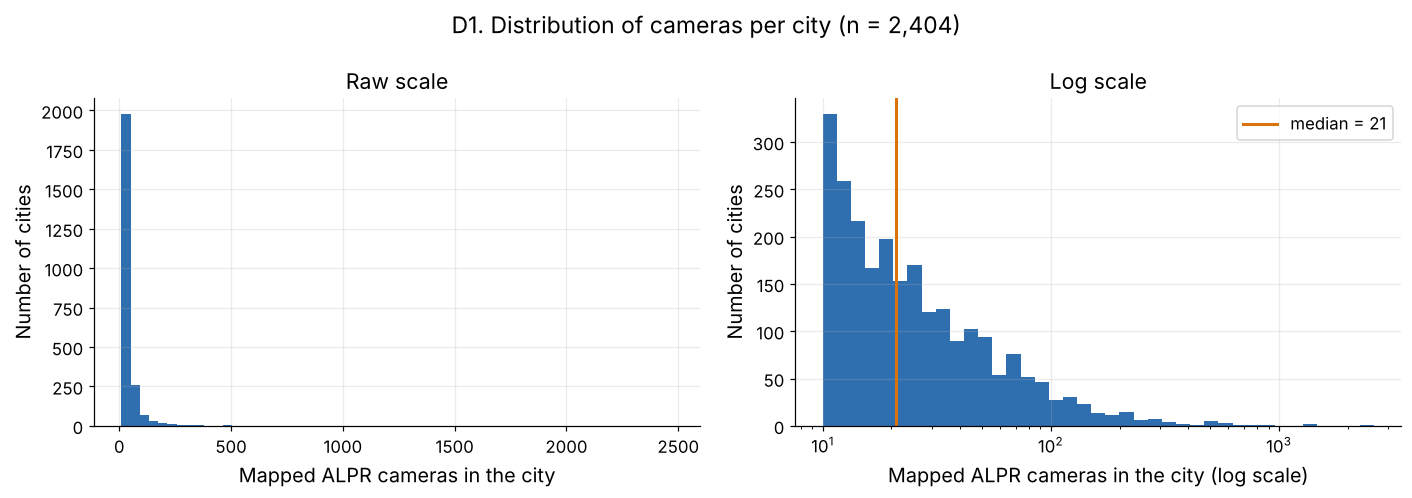

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].hist(city["cameras"], bins=60, color=BLUE)
ax[0].set(title="Raw scale", xlabel="Mapped ALPR cameras in the city", ylabel="Number of cities")
ax[1].hist(city["cameras"], bins=np.logspace(1, np.log10(2600), 40), color=BLUE)
ax[1].set_xscale("log")
ax[1].axvline(city["cameras"].median(), color=ORANGE, lw=2, label=f"median = {city['cameras'].median():.0f}")
ax[1].set(title="Log scale", xlabel="Mapped ALPR cameras in the city (log scale)", ylabel="Number of cities")
ax[1].legend()
fig.suptitle("D1. Distribution of cameras per city (n = 2,404)", fontsize=15)
fig.tight_layout(); plt.show()

**Shape.** Extremely right-skewed (skew ≈ 15). **Center:** median 21, mean 40. **Spread:** the middle half of cities
sits between 14 and 40 cameras; 99% are under 292. **Outliers:** 226 cities are above the box-plot fence of 79, and 11
have 500 or more, led by Houston (2,475), New York (1,345) and Chicago (1,333). On the raw scale nearly everything is in
the first bar, so the log scale is the readable one. Even on the log scale the distribution does not look bell-shaped:
it is a **wall at 10 that decays to the right**, the visible signature of the ≥ 10 cutoff (A1). Almost half of all
rows (1,170) have 20 cameras or fewer. The true distribution continues to the left of what we can see.

### D2. Land area and camera density

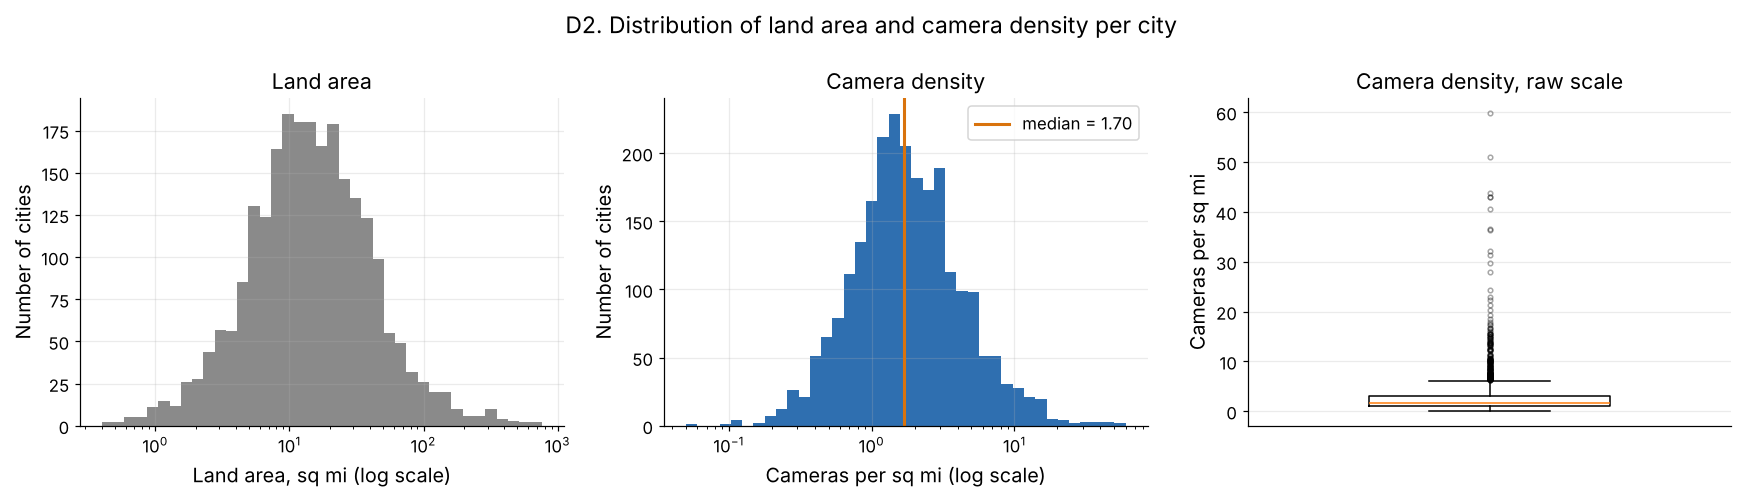

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].hist(city["land_sq_mi"], bins=np.logspace(np.log10(0.4), np.log10(760), 40), color=GREY)
ax[0].set_xscale("log"); ax[0].set(title="Land area", xlabel="Land area, sq mi (log scale)", ylabel="Number of cities")
ax[1].hist(city["cameras_per_sq_mi"], bins=np.logspace(np.log10(0.05), np.log10(60), 40), color=BLUE)
ax[1].set_xscale("log")
ax[1].axvline(city["cameras_per_sq_mi"].median(), color=ORANGE, lw=2, label=f"median = {city['cameras_per_sq_mi'].median():.2f}")
ax[1].set(title="Camera density", xlabel="Cameras per sq mi (log scale)", ylabel="Number of cities"); ax[1].legend()
ax[2].boxplot(city["cameras_per_sq_mi"], widths=0.5, flierprops=dict(marker="o", markersize=3, alpha=0.35))
ax[2].set(title="Camera density, raw scale", ylabel="Cameras per sq mi", xticks=[])
fig.suptitle("D2. Distribution of land area and camera density per city", fontsize=15)
fig.tight_layout(); plt.show()

**Shape.** Land area is right-skewed on the raw scale (median 14.2 sq mi, mean 26.7, max 747) and roughly symmetric
once logged. **Density** is the best-behaved feature in the file: on a log scale it is close to symmetric and
single-peaked (log skew ≈ 0.24), centered on a **median of 1.70 cameras per sq mi**, with the middle half between 1.0
and 3.05. On the raw scale (right panel, box plot) it still has a long upper tail: 199 cities are above the fence of 6.12, up to
59.85 (Youngtown, AZ). The top of that tail is almost entirely places under 2 sq mi, including a university campus
(A6), so the most extreme "densities" say more about small denominators than about heavy surveillance.

### D3. How much of each city's camera count is Flock

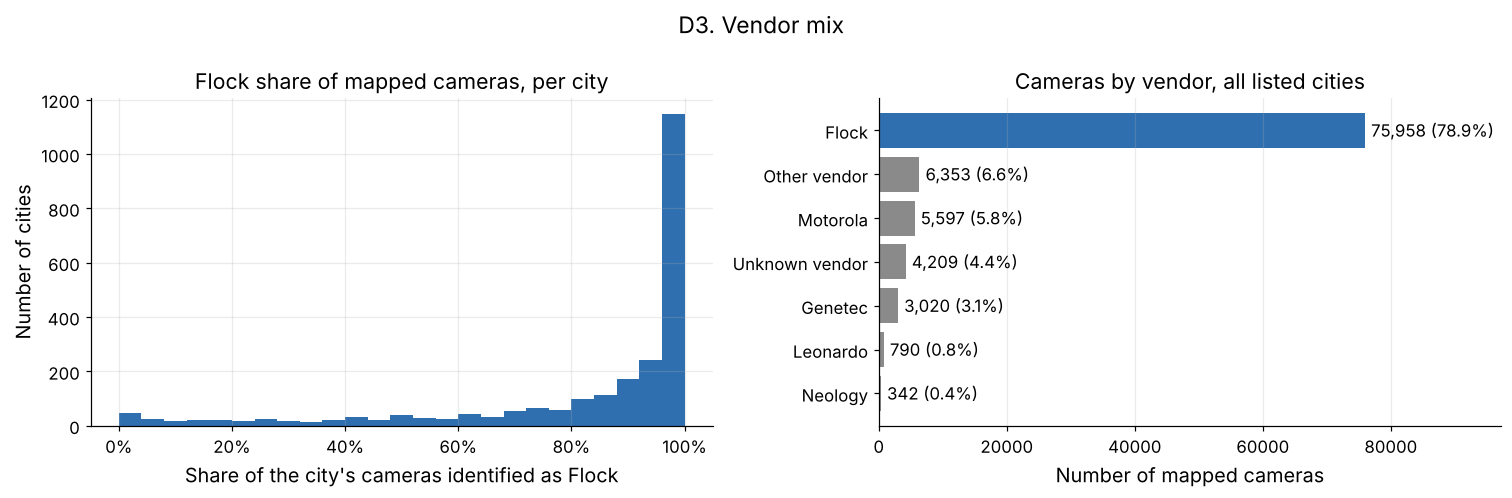

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].hist(city["flock_share"], bins=25, color=BLUE)
ax[0].set(title="Flock share of mapped cameras, per city", xlabel="Share of the city's cameras identified as Flock", ylabel="Number of cities")
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

totals = city.select(pl.col(VENDORS).sum()).row(0)
order = np.argsort(totals)
labels = [VENDORS[i].replace("_vendor", " vendor").capitalize() for i in order]
vals = [totals[i] for i in order]
bars = ax[1].barh(labels, vals, color=[BLUE if l == "Flock" else GREY for l in labels])
ax[1].bar_label(bars, labels=[f"{v:,} ({v / sum(totals):.1%})" for v in vals], padding=4, fontsize=11)
ax[1].set(title="Cameras by vendor, all listed cities", xlabel="Number of mapped cameras", xlim=(0, max(vals) * 1.28))
ax[1].grid(axis="y", visible=False)
fig.suptitle("D3. Vendor mix", fontsize=15)
fig.tight_layout(); plt.show()

**Shape.** `flock_share` is strongly **left-skewed and piled up at 100%**: median 0.95, mean 0.83. 945 cities (39%)
are entirely Flock and 1,514 (63%) are at least 90% Flock. There is a thin but real second group at the other end:
291 cities are under 50% Flock and 41 have **no** Flock cameras at all. Across all listed cities Flock accounts for
75,958 of 96,269 cameras (78.9%); the next largest named vendor, Motorola, has 5.8%. "Unknown" is 4.4% (A7).

**Why it matters:** our question is about *Flock* cameras, but a total camera count is not a Flock count. In most
cities the two are nearly the same thing; in a few hundred they are not, and (see R4) those few hundred include the
biggest cities.

### D4. Cameras per state

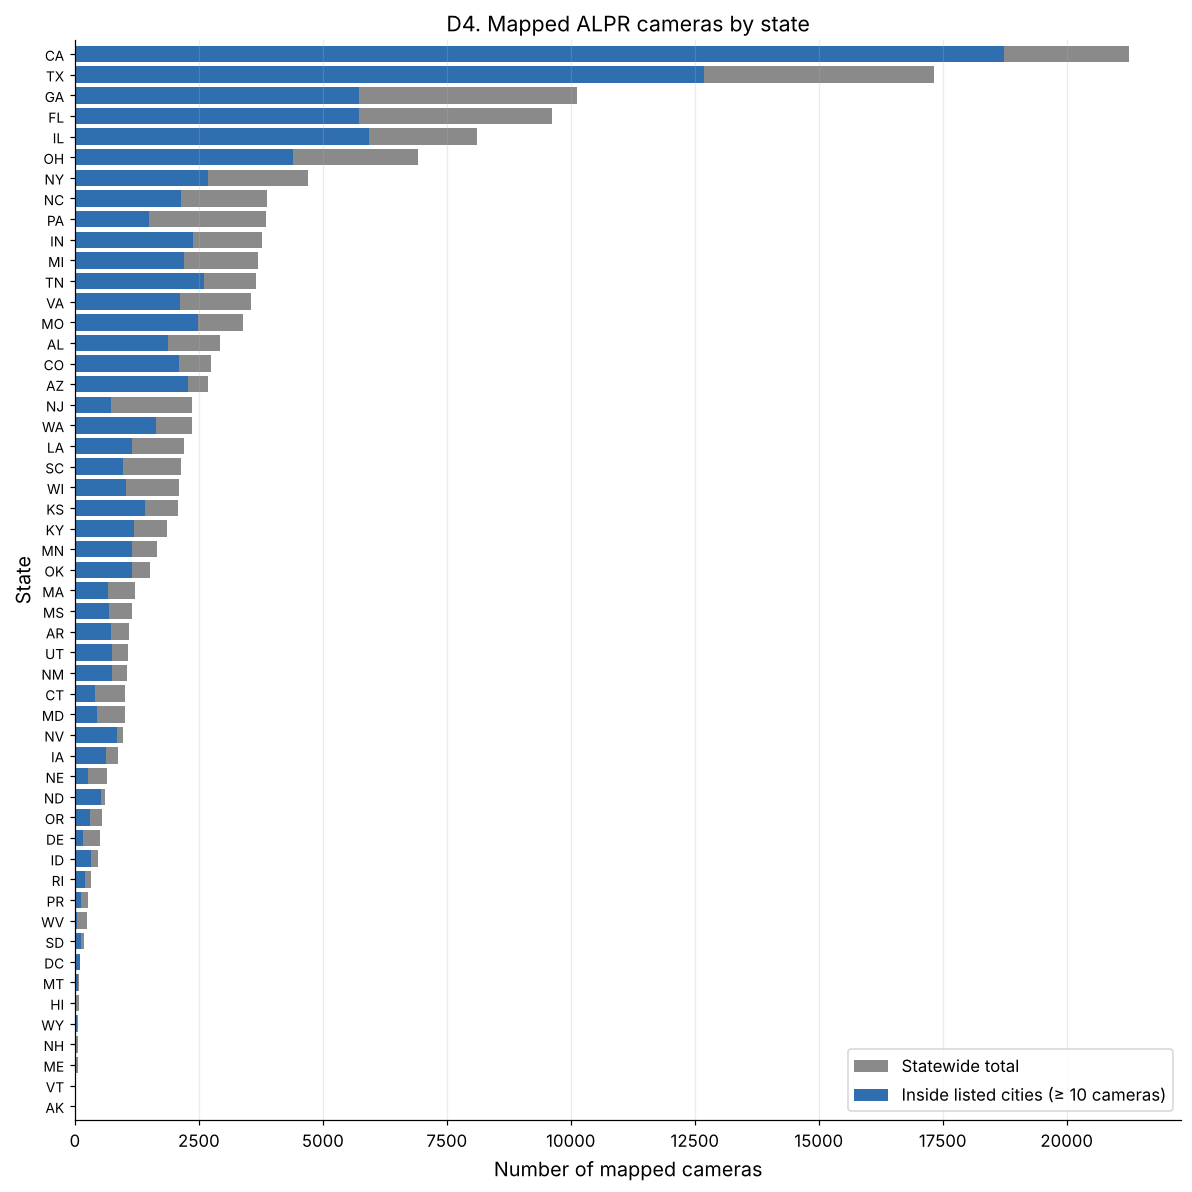

In [20]:
st = state.sort("cameras_statewide")
fig, ax = plt.subplots(figsize=(11, 11))
ax.barh(st["state"], st["cameras_statewide"], color=GREY, label="Statewide total")
ax.barh(st["state"], st["cameras_in_listed_cities"], color=BLUE, label="Inside listed cities (≥ 10 cameras)")
ax.set(title="D4. Mapped ALPR cameras by state", xlabel="Number of mapped cameras", ylabel="State")
ax.tick_params(axis="y", labelsize=9); ax.grid(axis="y", visible=False); ax.margins(y=0.005)
ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

**Shape.** Right-skewed again, with only 52 points. **Center:** median 1,522 cameras, mean 2,773. **Spread:** from 24
(Alaska) to 21,251 (California). The top five states (CA, TX, GA, FL, IL) hold 46% of all mapped cameras. California
and Texas are outliers by any rule. Georgia in third place, ahead of Florida and New York, is the one surprise: it is
Flock's home state. These are raw counts, not per-capita rates, so most of the ordering is just population. The grey
part of each bar is cameras outside any listed city, which R3 looks at.

## 4–6. Relationships, with "so what?" and "what next?"

Four plots. R3 is the one that uses the join between the primary (city) and secondary (state) tables.

### R1. Do bigger cities have more cameras? (scatter)

log-log slope = 0.43, Pearson r (log-log) = 0.58, Spearman rho = 0.52


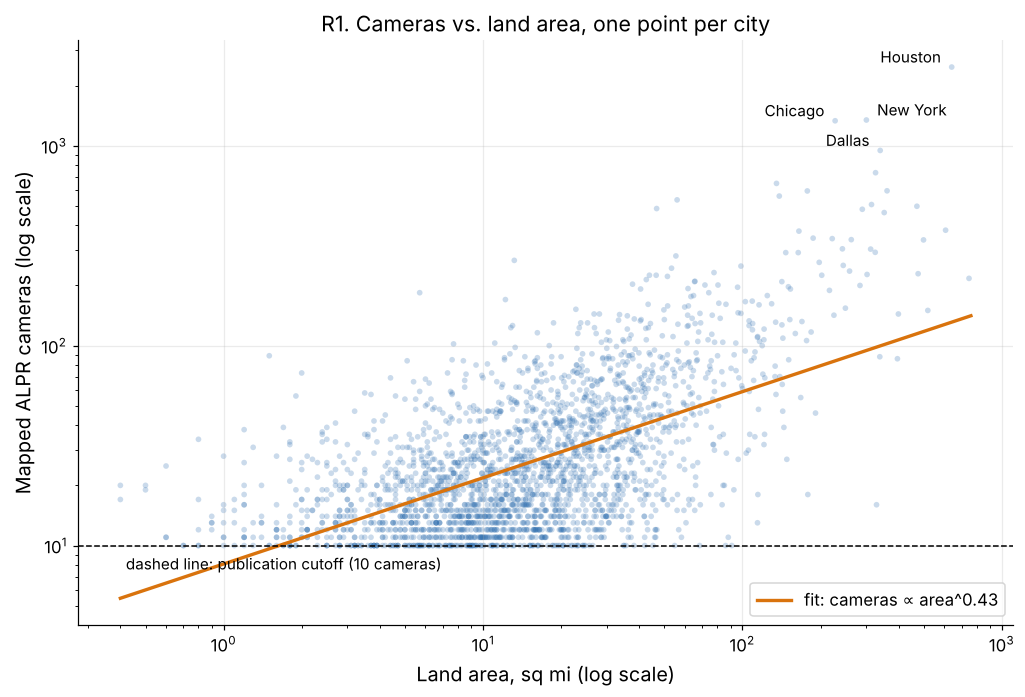

In [21]:
x, y = city["log_land"].to_numpy(), city["log_cameras"].to_numpy()
slope, intercept = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]
rho = city.select(pl.corr("cameras", "land_sq_mi", method="spearman")).item()
print(f"log-log slope = {slope:.2f}, Pearson r (log-log) = {r:.2f}, Spearman rho = {rho:.2f}")

fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.scatter(city["land_sq_mi"], city["cameras"], s=14, alpha=0.25, color=BLUE, edgecolors="none")
xs = np.logspace(np.log10(0.4), np.log10(760), 50)
ax.plot(xs, 10 ** (intercept + slope * np.log10(xs)), color=ORANGE, lw=2.2, label=f"fit: cameras ∝ area^{slope:.2f}")
ax.axhline(10, color="black", lw=1, ls="--")
ax.text(0.42, 7.6, "dashed line: publication cutoff (10 cameras)", fontsize=10)
for row in city.sort("cameras", descending=True).head(4).iter_rows(named=True):
    right = row["city"] == "New York"
    ax.annotate(row["city"], (row["land_sq_mi"], row["cameras"]), xytext=(7 if right else -7, 3), textcoords="offset points",
                ha="left" if right else "right", fontsize=10)
ax.set(xscale="log", yscale="log", xlabel="Land area, sq mi (log scale)", ylabel="Mapped ALPR cameras (log scale)",
       title="R1. Cameras vs. land area, one point per city")
ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

**So what?** Cameras rise with city size, but much more slowly than proportionally: the fitted slope is about 0.43,
so a city with ten times the area has only about 2.7 times the cameras (Pearson r = 0.58 on the log scale, Spearman
ρ = 0.52). This was **expected in direction, unexpected in strength**: we assumed camera counts were mostly a
size effect, and size explains only about a third of the variance. Two cities of the same area routinely differ by
a factor of ten. That leftover variation is good news for the research question, because it is the variation a
crime comparison would need. The flat floor at 10 is the cutoff (A1) again, and it biases the slope downward:
small-area cities with few cameras are missing, so the left side of the cloud is artificially lifted.

It matters because **raw camera counts cannot be the treatment variable**. Large cities have more cameras and, for
unrelated reasons, more crime; comparing counts to crime would mostly rediscover city size.

**What next?** Land area is the wrong denominator. Join **population** by `geoid` (Census ACS place-level table
B01003, the place-level version of what we already pulled for ZIP codes) and redo this as cameras per 1,000
residents. Then ask: does the size relationship look the same within a single state?

### R2. Is camera density the same across states? (subgroup comparison)

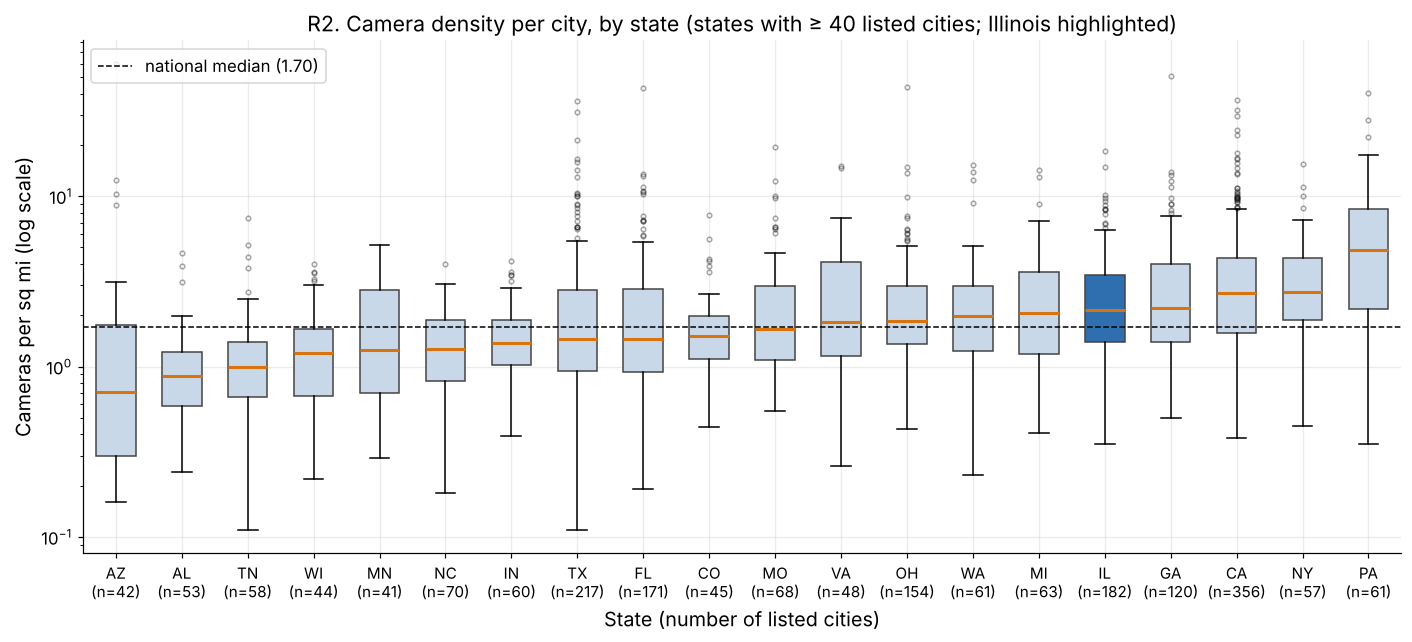

state,n,med
str,u32,f64
"""AZ""",42,0.71
"""AL""",53,0.88
"""TN""",58,1.0
"""WI""",44,1.195
"""MN""",41,1.25
"""NC""",70,1.27
"""IN""",60,1.37
"""TX""",217,1.45
"""FL""",171,1.46


In [22]:
big = city.group_by("state").agg(pl.len().alias("n"), pl.col("cameras_per_sq_mi").median().alias("med")).filter(pl.col("n") >= 40).sort("med")
groups = [city.filter(pl.col("state") == s)["cameras_per_sq_mi"].to_numpy() for s in big["state"]]

fig, ax = plt.subplots(figsize=(13, 6))
bp = ax.boxplot(groups, tick_labels=[f"{s}\n(n={n})" for s, n in zip(big["state"], big["n"])], patch_artist=True, widths=0.6,
                flierprops=dict(marker="o", markersize=3, alpha=0.35), medianprops=dict(color=ORANGE, lw=2))
for patch, s in zip(bp["boxes"], big["state"]):
    patch.set(facecolor=BLUE if s == "IL" else "#c9d8e8", edgecolor="#444")
ax.axhline(city["cameras_per_sq_mi"].median(), color="black", ls="--", lw=1, label="national median (1.70)")
ax.set(yscale="log", ylabel="Cameras per sq mi (log scale)", xlabel="State (number of listed cities)",
       title="R2. Camera density per city, by state (states with ≥ 40 listed cities; Illinois highlighted)")
ax.tick_params(axis="x", labelsize=10); ax.legend(loc="upper left")
fig.tight_layout(); plt.show()
big

**So what?** The distribution of density is **not** the same across states. Among the 20 states with at least 40
listed cities, the median city ranges from 0.71 cameras per sq mi in Arizona to 4.81 in Pennsylvania, a factor of
almost seven, and the boxes for the two ends barely overlap. Illinois (median 2.16, n = 182) sits in the upper third,
above the national median of 1.70. Some of this was **expected**: Arizona and Alabama cities annex large amounts of
empty land, while Pennsylvania boroughs are tiny, so part of the gap is the denominator, not the cameras.
The size of the Pennsylvania gap was **unexpected**, and it is suspicious rather than exciting: Pennsylvania is also
the least-Flock state in the group (median Flock share 18%), which suggests a different kind of camera (fixed
traffic or toll-style readers) or a different mapping community.

It matters because state is a strong confounder. State also drives crime rates, crime reporting rules and how
actively volunteers map cameras. A pooled national camera-vs-crime comparison would mix all of that in.

**What next?** Compare cities **within** a state, or include state as a control. Split out Pennsylvania and New York
to see which vendors and place types drive their high density. Ask someone who maps for DeFlock/OSM whether mapping
effort is known to be uneven by state, since we cannot tell "more cameras" from "more mappers" with this file alone.

### R3. How much of each state's camera total does the city file capture? (join: city → state)

The city table is aggregated to one row per state and joined to the state table on `state`. First the join is
validated, then used.

In [23]:
city_by_state = city.group_by("state").agg(
    pl.len().alias("n_cities_in_city_file"),
    pl.col("cameras").sum().alias("cameras_in_city_file"),
    pl.col("flock").sum().alias("flock_in_city_file"),
)
joined = state.join(city_by_state, on="state", how="left", validate="1:1").with_columns(
    pl.col("n_cities_in_city_file", "cameras_in_city_file", "flock_in_city_file").fill_null(0)
)

print("state rows:", state.height, "| joined rows:", joined.height,
      "| states with no match in the city file:", joined.filter(pl.col("n_cities_in_city_file") == 0)["state"].to_list())
print("city-file states missing from the state file:", city_by_state.join(state, on="state", how="anti").height)
print("city count disagrees :", joined.filter(pl.col("n_cities_in_city_file") != pl.col("listed_cities")).height)
print("camera sum disagrees :", joined.filter(pl.col("cameras_in_city_file") != pl.col("cameras_in_listed_cities")).height)
print("flock sum disagrees  :", joined.filter(pl.col("flock_in_city_file") != pl.col("flock")).height)
print(f"overall share of mapped cameras that fall inside a listed city: {joined['cameras_in_city_file'].sum() / joined['cameras_statewide'].sum():.1%}")

state rows: 52 | joined rows: 52 | states with no match in the city file: ['NH', 'VT', 'AK']
city-file states missing from the state file: 0
city count disagrees : 0
camera sum disagrees : 0
flock sum disagrees  : 0
overall share of mapped cameras that fall inside a listed city: 66.8%


Spearman rho (coverage vs statewide total) = 0.25


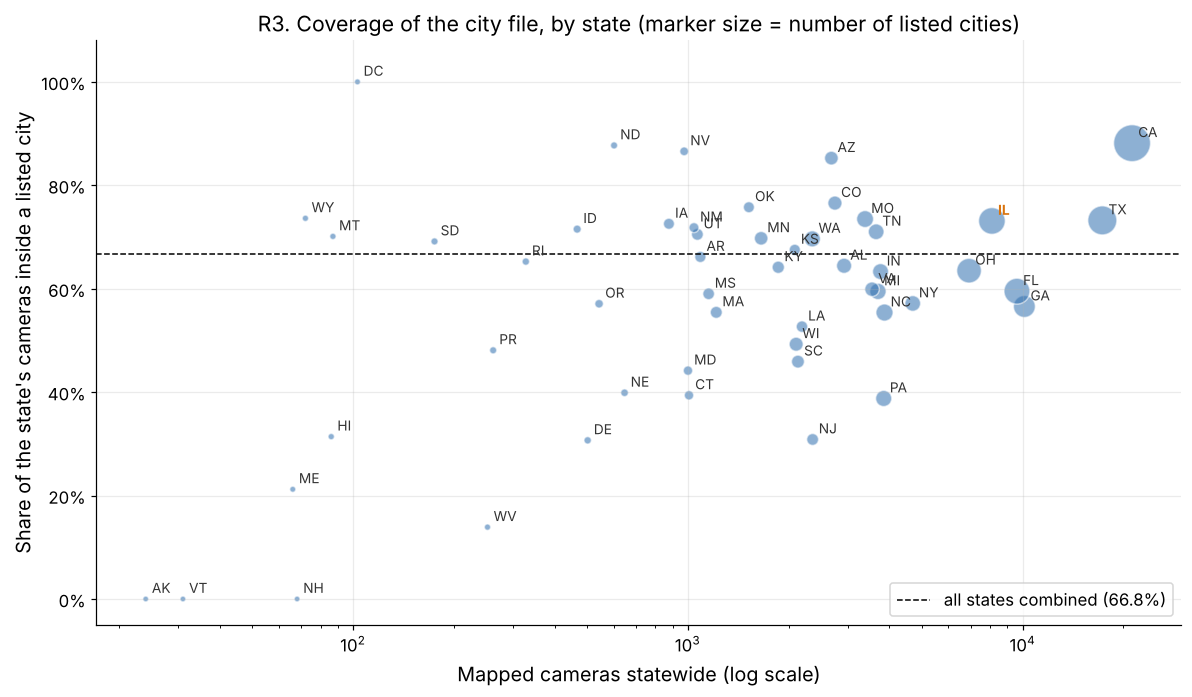

state,cameras_statewide,listed_cities,cameras_outside_listed_cities,city_coverage
str,i64,i64,i64,f64
"""NH""",68,0,68,0.0
"""VT""",31,0,31,0.0
"""AK""",24,0,24,0.0
"""WV""",252,2,217,0.138889
"""ME""",66,1,52,0.212121
"""DE""",502,6,348,0.306773
"""NJ""",2360,29,1632,0.308475
"""HI""",86,2,59,0.313953
"""PA""",3848,61,2356,0.387734


In [24]:
rho_cov = joined.select(pl.corr("city_coverage", "cameras_statewide", method="spearman")).item()
print(f"Spearman rho (coverage vs statewide total) = {rho_cov:.2f}")

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(joined["cameras_statewide"], joined["city_coverage"], s=joined["listed_cities"] * 1.6 + 14, alpha=0.55, color=BLUE, edgecolors="white")
for row in joined.iter_rows(named=True):
    ax.annotate(row["state"], (row["cameras_statewide"], row["city_coverage"]), xytext=(4, 4), textcoords="offset points",
                fontsize=9, color=ORANGE if row["state"] == "IL" else "#333", fontweight="bold" if row["state"] == "IL" else "normal")
ax.axhline(joined["cameras_in_city_file"].sum() / joined["cameras_statewide"].sum(), color="black", ls="--", lw=1, label="all states combined (66.8%)")
ax.set(xscale="log", xlabel="Mapped cameras statewide (log scale)", ylabel="Share of the state's cameras inside a listed city",
       title="R3. Coverage of the city file, by state (marker size = number of listed cities)", ylim=(-0.05, 1.08))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

joined.sort("city_coverage").select("state", "cameras_statewide", "listed_cities", "cameras_outside_listed_cities", "city_coverage").head(12)

**So what?** The join is clean: all 52 states match, and the city file's per-state city counts, camera sums and Flock
sums reproduce the state file exactly, so the two files are consistent with each other. What the join reveals is
how much the city file **leaves out**: only **66.8%** of mapped cameras (96,269 of 144,208) are inside a listed city.
The other third, about 47,900 cameras, are in places under the 10-camera cutoff, in unincorporated areas or on highways.

Coverage is very uneven. California (88%), Arizona (85%) and Nevada (87%) are well covered. New Jersey (31%),
Pennsylvania (39%) and Connecticut (39%) are not, and New Hampshire, Vermont and Alaska are at 0%. Illinois is at
73%. That coverage is incomplete was **expected**; that it depends so much on the state was **unexpected**, and it
is only weakly related to how many cameras the state has (Spearman ρ ≈ 0.25). The pattern looks more like local
government structure: north-eastern states are split into many small boroughs and townships, each below the cutoff.

It matters because a city-level camera-vs-crime study built on this file would silently describe western and
southern cities much better than north-eastern ones, and would treat small-town deployments, which are a large part
of Flock's business, as if they did not exist.

**What next?** For Illinois we already have every individual camera in `Illinois_alpr.geojson`. Assign those points
to places (and to ZIP codes, as planned) ourselves, so that the 27% of Illinois cameras outside listed cities and
all the places with 1–9 cameras come back. That also gives the low-exposure comparison group that this file lacks.

### R4. Is the Flock share the same in small and large deployments? (subgroup comparison)

Spearman rho (flock_share vs cameras) = -0.20


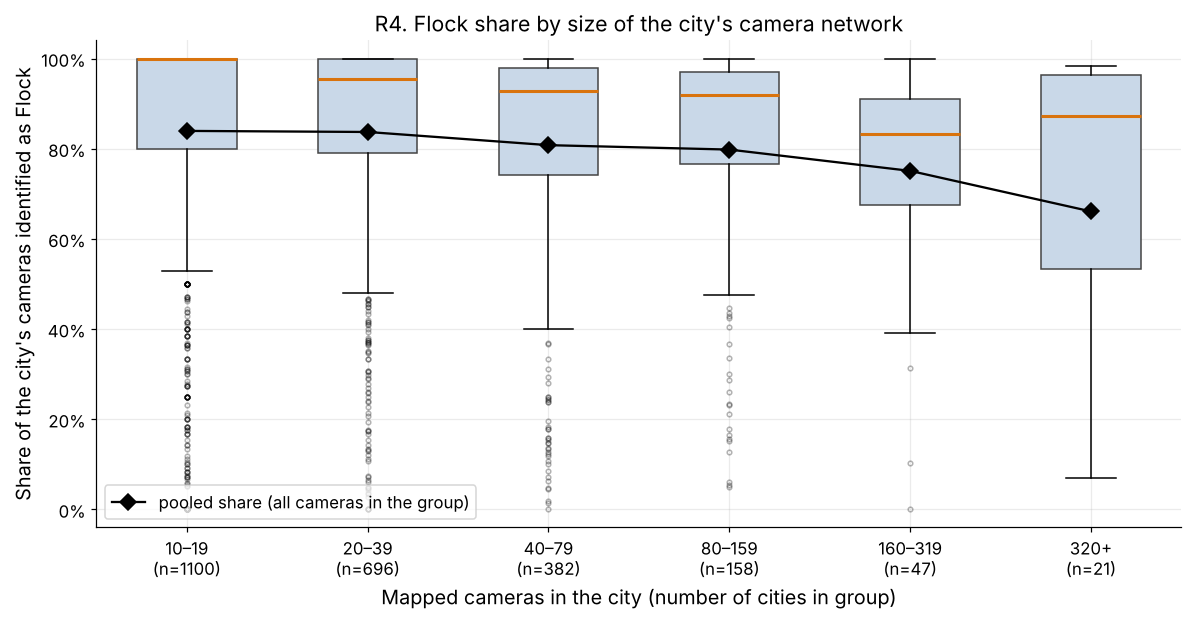

size_bin,n_cities,cameras,flock,median_city_flock_share,share_of_cities_under_half_flock,pooled_flock_share
str,u32,i64,i64,f64,f64,f64
"""10–19""",1100,14908,12515,1.0,0.118182,0.839482
"""20–39""",696,19093,15983,0.954545,0.112069,0.837113
"""40–79""",382,20967,16939,0.928571,0.13089,0.807889
"""80–159""",158,16888,13478,0.91818,0.139241,0.798081
"""160–319""",47,10095,7580,0.831897,0.12766,0.750867
"""320+""",21,14318,9463,0.87172,0.238095,0.660916


In [25]:
edges = [10, 20, 40, 80, 160, 320, 10_000]
names = ["10–19", "20–39", "40–79", "80–159", "160–319", "320+"]
bin_index = np.digitize(city["cameras"].to_numpy(), edges[1:-1])  # 0 = 10–19, ..., 5 = 320+
binned = city.with_columns(pl.Series("bin_index", bin_index), pl.Series("size_bin", [names[i] for i in bin_index]))
by_bin = (
    binned.group_by("bin_index", "size_bin")
    .agg(pl.len().alias("n_cities"), pl.col("cameras").sum().alias("cameras"), pl.col("flock").sum().alias("flock"),
         pl.col("flock_share").median().alias("median_city_flock_share"),
         (pl.col("flock_share") < 0.5).mean().alias("share_of_cities_under_half_flock"))
    .with_columns((pl.col("flock") / pl.col("cameras")).alias("pooled_flock_share"))
    .sort("bin_index").drop("bin_index")
)
rho_fs = city.select(pl.corr("flock_share", "cameras", method="spearman")).item()
print(f"Spearman rho (flock_share vs cameras) = {rho_fs:.2f}")

fig, ax = plt.subplots(figsize=(11, 5.8))
groups = [binned.filter(pl.col("size_bin") == n)["flock_share"].to_numpy() for n in names]
ax.boxplot(groups, tick_labels=[f"{n}\n(n={len(g)})" for n, g in zip(names, groups)], patch_artist=True, widths=0.55,
           boxprops=dict(facecolor="#c9d8e8", edgecolor="#444"), medianprops=dict(color=ORANGE, lw=2),
           flierprops=dict(marker="o", markersize=3, alpha=0.3))
ax.plot(range(1, len(names) + 1), by_bin["pooled_flock_share"], "D-", color="black", ms=7, label="pooled share (all cameras in the group)")
ax.set(xlabel="Mapped cameras in the city (number of cities in group)", ylabel="Share of the city's cameras identified as Flock",
       title="R4. Flock share by size of the city's camera network", ylim=(-0.04, 1.04))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="lower left")
fig.tight_layout(); plt.show()
by_bin

**So what?** Flock's share falls as the camera network gets bigger. In cities with 10–19 cameras the typical
(median) city is 100% Flock and Flock holds 84% of all cameras in the group. In the 21 cities with 320 or more
cameras the pooled Flock share is 66%, and about one in four of those cities is less than half Flock, against 11–14% in
every smaller group. The city-level correlation is weak (Spearman ρ = −0.20) because most cities of every
size are still mostly Flock; the effect comes from a minority of large cities. New York (7% Flock), Chicago (7%) and
San Diego (14%) are the clearest cases: three of the five largest networks in the country are barely Flock at all.
This was **somewhere in between**: we knew big departments ran older systems from Motorola and others, but did not
expect the largest deployments to be the *least* Flock.

It matters because the research question names Flock specifically. If we use total cameras as the measure, the
biggest cities, which also have the most crime and the most influence on any pooled result, would be counted as
heavy "Flock" cities when they are not. Chicago is in our own state.

**What next?** Use `flock` (or `flock_share`) rather than `cameras` as the exposure, and run the comparison
separately for Flock and non-Flock cameras. Check Chicago, New York and San Diego against the Atlas of
Surveillance `Vendor` column to confirm the vendor mix, since 351 of Chicago's cameras are "unknown vendor". The 21
largest cities are few enough to check by hand.

## Research questions, revisited

**Original:** *Do Flock cameras reduce crime rates in their region?*

**What the data did to it.** Nothing in this dataset can support the word "reduce". It is one snapshot (October
2026) with no install dates and no crime figures, and every city in it already has cameras. The honest best case for a
single snapshot plus crime data is an association, and even that would be confounded by city size (R1) and state (R2),
and built on a sample that excludes a third of all cameras (R3) and blurs Flock with other vendors in the largest
cities (R4). Cities also tend to buy cameras *because* crime is high, so a naive comparison could easily show more
cameras going with more crime.

**Revised questions**

1. **Exposure (answerable now):** How does ALPR camera density vary across US cities and states, and how much of it is Flock?
2. **Association (needs one join):** Among cities in the same state and of similar size, is higher Flock camera
   density per resident associated with lower property and vehicle-theft crime rates?
3. **Change over time (the causal version, needs dates):** In cities where we can date the Flock deployment, did
   vehicle-theft and property-crime rates change after installation relative to similar cities that had not yet deployed?

**What changed and why.** "Reduce" became "is associated with" for the cross-section, with the causal claim moved to a
separate question that needs before/after data. "Crime" narrowed to vehicle theft and property crime, the offences
plate readers are sold to address. "Their region" became the city (Census place), because that is the unit this data
and police crime reporting share. "Cameras" became Flock cameras per resident, because of R1 and R4.

**Data still needed**

| Need | Source | Join key |
|---|---|---|
| Crime counts by agency and year | FBI Crime Data Explorer (NIBRS / Summary Reporting System) | agency → Census place `geoid` via the BJS Law Enforcement Agency Identifiers Crosswalk |
| Population by place | Census ACS 5-year, table B01003, place level | `geoid` |
| Deployment dates | Eyes On Flock portal data and Atlas of Surveillance `Link 1 Date` (both already in the repo) | city + state, then `geoid` |
| Cities below the 10-camera cutoff | our own `Illinois_alpr.geojson` points assigned to places | point-in-polygon |